# Inside the Cs-137 models

> Which wavenumbers drive the Cs-137 ratio predictions, and how the clay-mineral bands near 3620 and 3695 cm⁻¹ relate to the ratio by soil type

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from fastai.torch_core import set_seed
from fastcore.test import *
from soilspectfm.preprocessing import SNV
from soilspecdl.all import spectral_learner, SpectralCNN, CutCNN, ridge_head, predict, regression_scores
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.importance import integrated_gradients, occlusion, region_shares
from ossl_fuku_transfer.bands import sharp_bands, band_depth

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Cs-137 is fixed at the frayed edges of illite and other micas, so the ratio of exchangeable to total Cs-137 should depend on those clay minerals. `17_importance` found that the OSSL Kex model relies most on the Al–OH band near 3620 cm⁻¹, part of their signature. `18_aloh` found that in Fukushima's Lowland soils, the clay-mineral bands correlate negatively with clay, the reverse of OSSL. This notebook asks the same questions of the Cs-137 ratio.

Every code cell reads the Fukushima data or the saved OSSL models, and is marked `#| fukudata`.

## Data and models

The Cs-137 ratio of `10_cs137` (log10 of exchangeable over total Cs-137), the current selection of Fukushima spectra, and the Cs137 study's test set. Two models:

- `frozen OSSL`: block 4 of the OSSL Kex model, frozen, with a ridge regression on its flattened output, as in `10_cs137`. It is built with `CutCNN` and `ridge_head` from soilspecdl, so integrated gradients apply to it.
- `Fukushima only`: the CNN from random weights, trained on the Fukushima training samples for 40 epochs at a maximum learning rate of 3·10⁻³, the Kex schedule of `03_kex`, not tuned for the ratio.

Their test scores:

In [ ]:
#| fukudata
ref = fuku_path()/'reference'
ratio = pd.concat([pd.read_csv(ref/f'cs137_ratio_{s}.csv', usecols=['ID', 'exCs137_totalCs137']) for s in ('train', 'test')])
ratio = ratio.assign(ID=ratio.ID.astype(str)).set_index('ID')['exCs137_totalCs137']
fuku = load_fuku()
fuku.source = fuku.source.assign(target=ratio)
Xf, yf, idf = fuku.xy('target')
yf = yf.ravel()
Xf_d = preprocessings()['snv_d1'].fit_transform(Xf)
is_test = np.isin(idf, cs137_split()[1])
tr = np.flatnonzero(~is_test)
models = {'frozen OSSL': ridge_head(CutCNN(load_pretrained('ossl_kex_snv_d1'), len(shared_wns), flat=True), Xf_d[tr], yf[tr], shared_wns)}
set_seed(0)
learn = spectral_learner(fuku_dls(Xf_d, yf, is_test, seed=0), SpectralCNN())
with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(40, lr_max=3e-3)
models['Fukushima only'] = learn.model.cpu()
pd.DataFrame({m: regression_scores(yf[is_test], predict(model, Xf_d[is_test], shared_wns)) for m, model in models.items()}).round(3)

,frozen OSSL,Fukushima only
R²,0.641,0.569
r,0.805,0.763
RMSE,0.207,0.226
bias,0.030,0.038


## Wavenumber importance

The mean absolute integrated gradient per wavenumber on the test spectra, scaled to sum to 1, with the band assignments and regions of `17_importance`:

,frozen OSSL,Fukushima only
frozen OSSL,1.00,0.36
Fukushima only,0.36,1.00


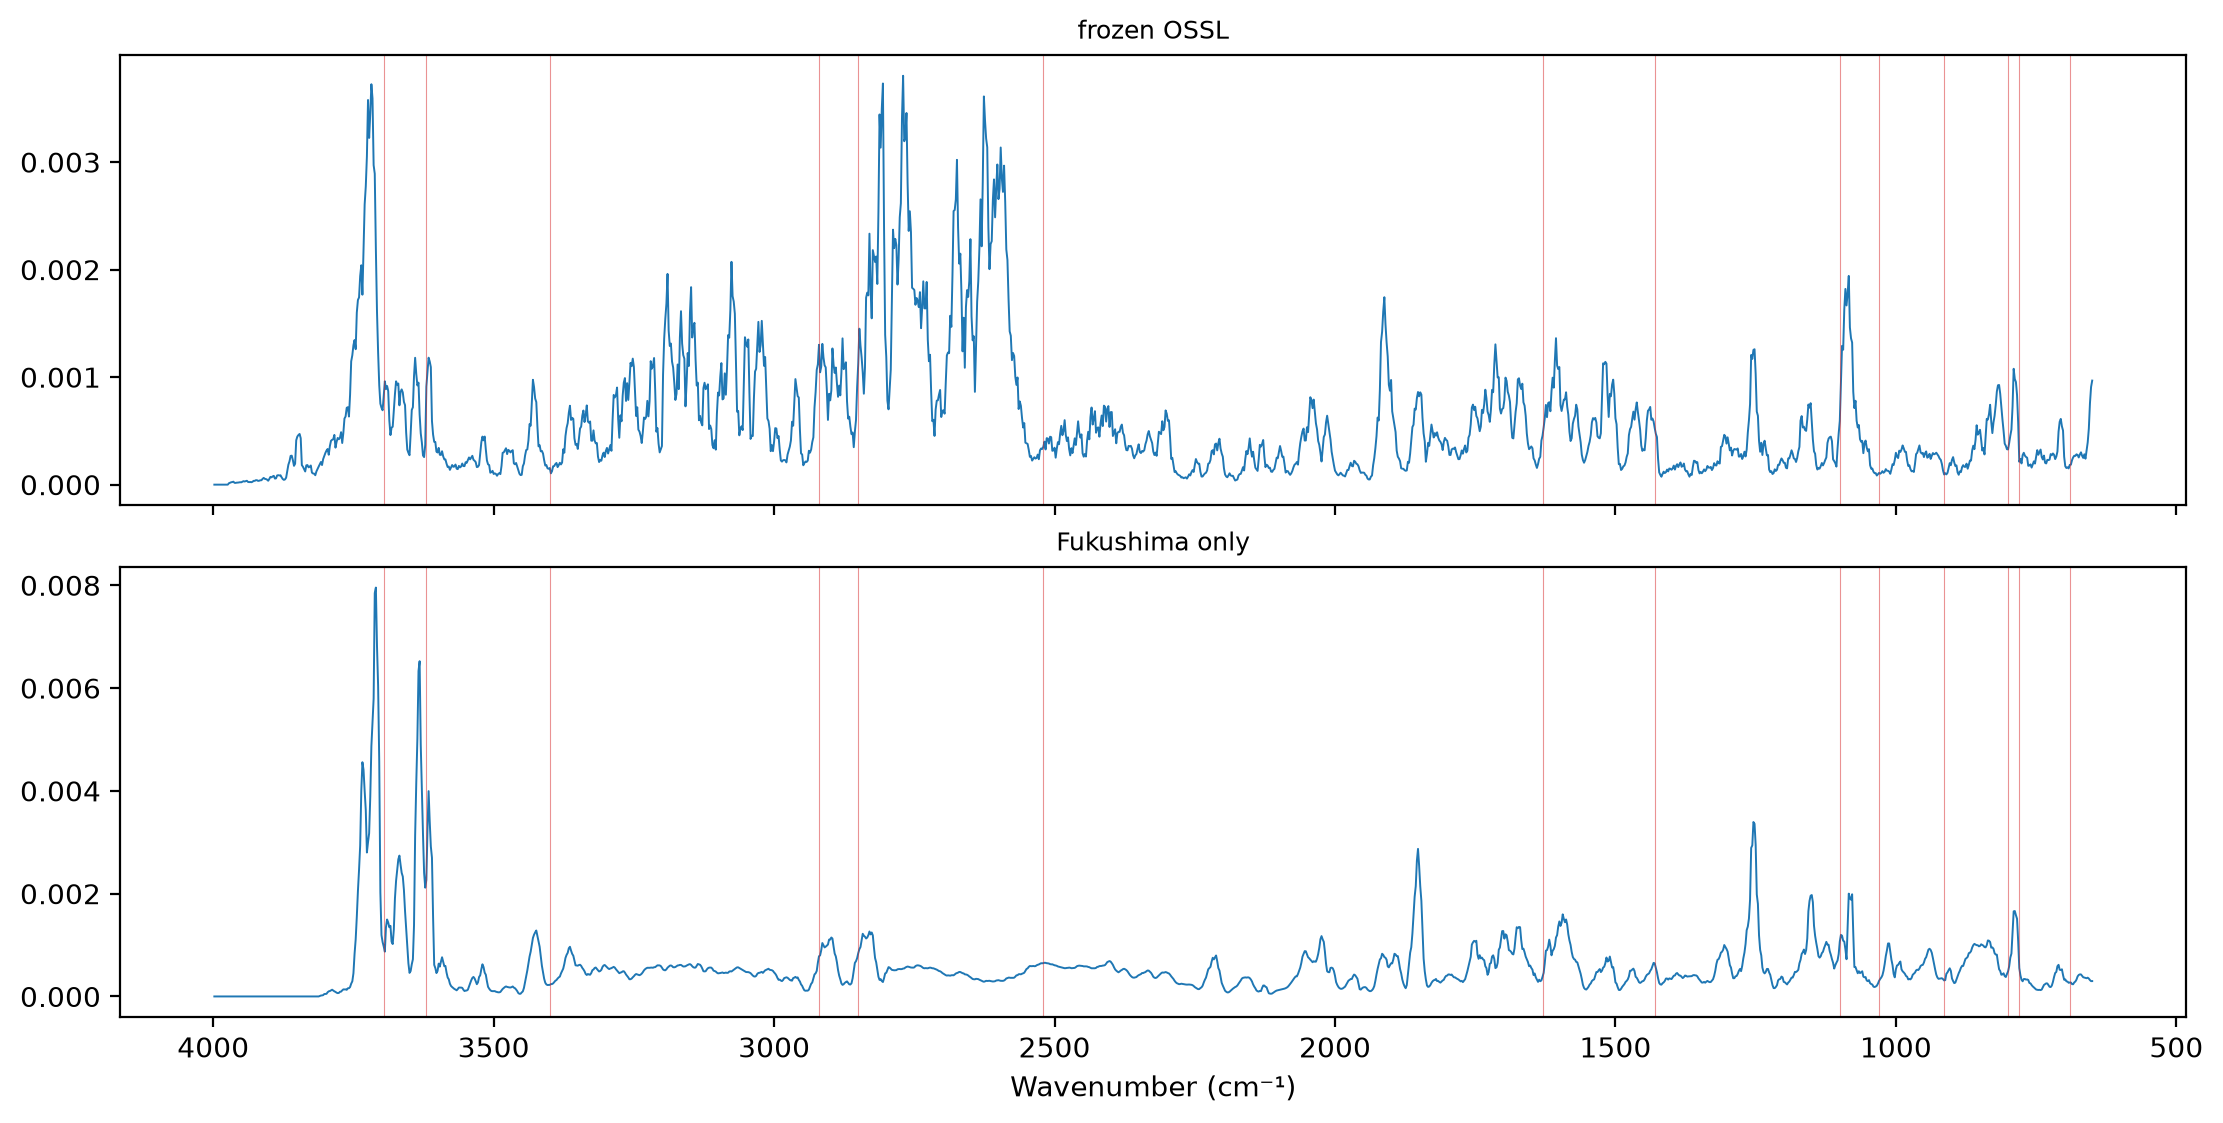

,frozen OSSL,Fukushima only
650–1300,0.124,0.216
1300–2000,0.164,0.204
2000–2800,0.316,0.179
2800–3200,0.202,0.110
3200–3600,0.081,0.087
3600–3700,0.036,0.108
3700–3998,0.079,0.101


In [ ]:
#| fukudata
bands = {3695: 'kaolinite OH', 3620: 'kaolinite, illite, smectite Al–OH', 3400: 'H-bonded O–H', 2920: 'aliphatic C–H', 2850: 'aliphatic C–H',
         2520: 'carbonate', 1630: 'H–O–H, amide, carboxylate', 1430: 'carbonate, carboxylate', 1100: 'Si–O', 1030: 'Si–O, clay',
         915: 'kaolinite Al–OH', 800: 'quartz', 780: 'quartz', 690: 'quartz'}
regions = {'650–1300': (650, 1300), '1300–2000': (1300, 2000), '2000–2800': (2000, 2800), '2800–3200': (2800, 3200),
           '3200–3600': (3200, 3600), '3600–3700': (3600, 3700), '3700–3998': (3700, 3998)}
prof = {}
for m, model in models.items():
    a = np.abs(integrated_gradients(model, Xf_d[is_test])).mean(0)
    prof[m] = a / a.sum()
prof = pd.DataFrame(prof, index=shared_wns)
fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, layout='constrained')
for ax, m in zip(axs, prof):
    ax.plot(shared_wns, prof[m].rolling(5, center=True, min_periods=1).mean(), lw=0.7); ax.set_title(m, fontsize=9)
    for w in bands: ax.axvline(w, lw=0.4, c='tab:red', alpha=0.5)
axs[-1].invert_xaxis(); axs[-1].set_xlabel('Wavenumber (cm⁻¹)')
display(prof.rolling(5, center=True, min_periods=1).mean().corr().round(2))
pd.DataFrame({m: region_shares(prof[m], shared_wns, regions) for m in prof}).round(3)

The rise in mean squared error when each 40 cm⁻¹ window is flattened, and the five windows that matter most for each model:

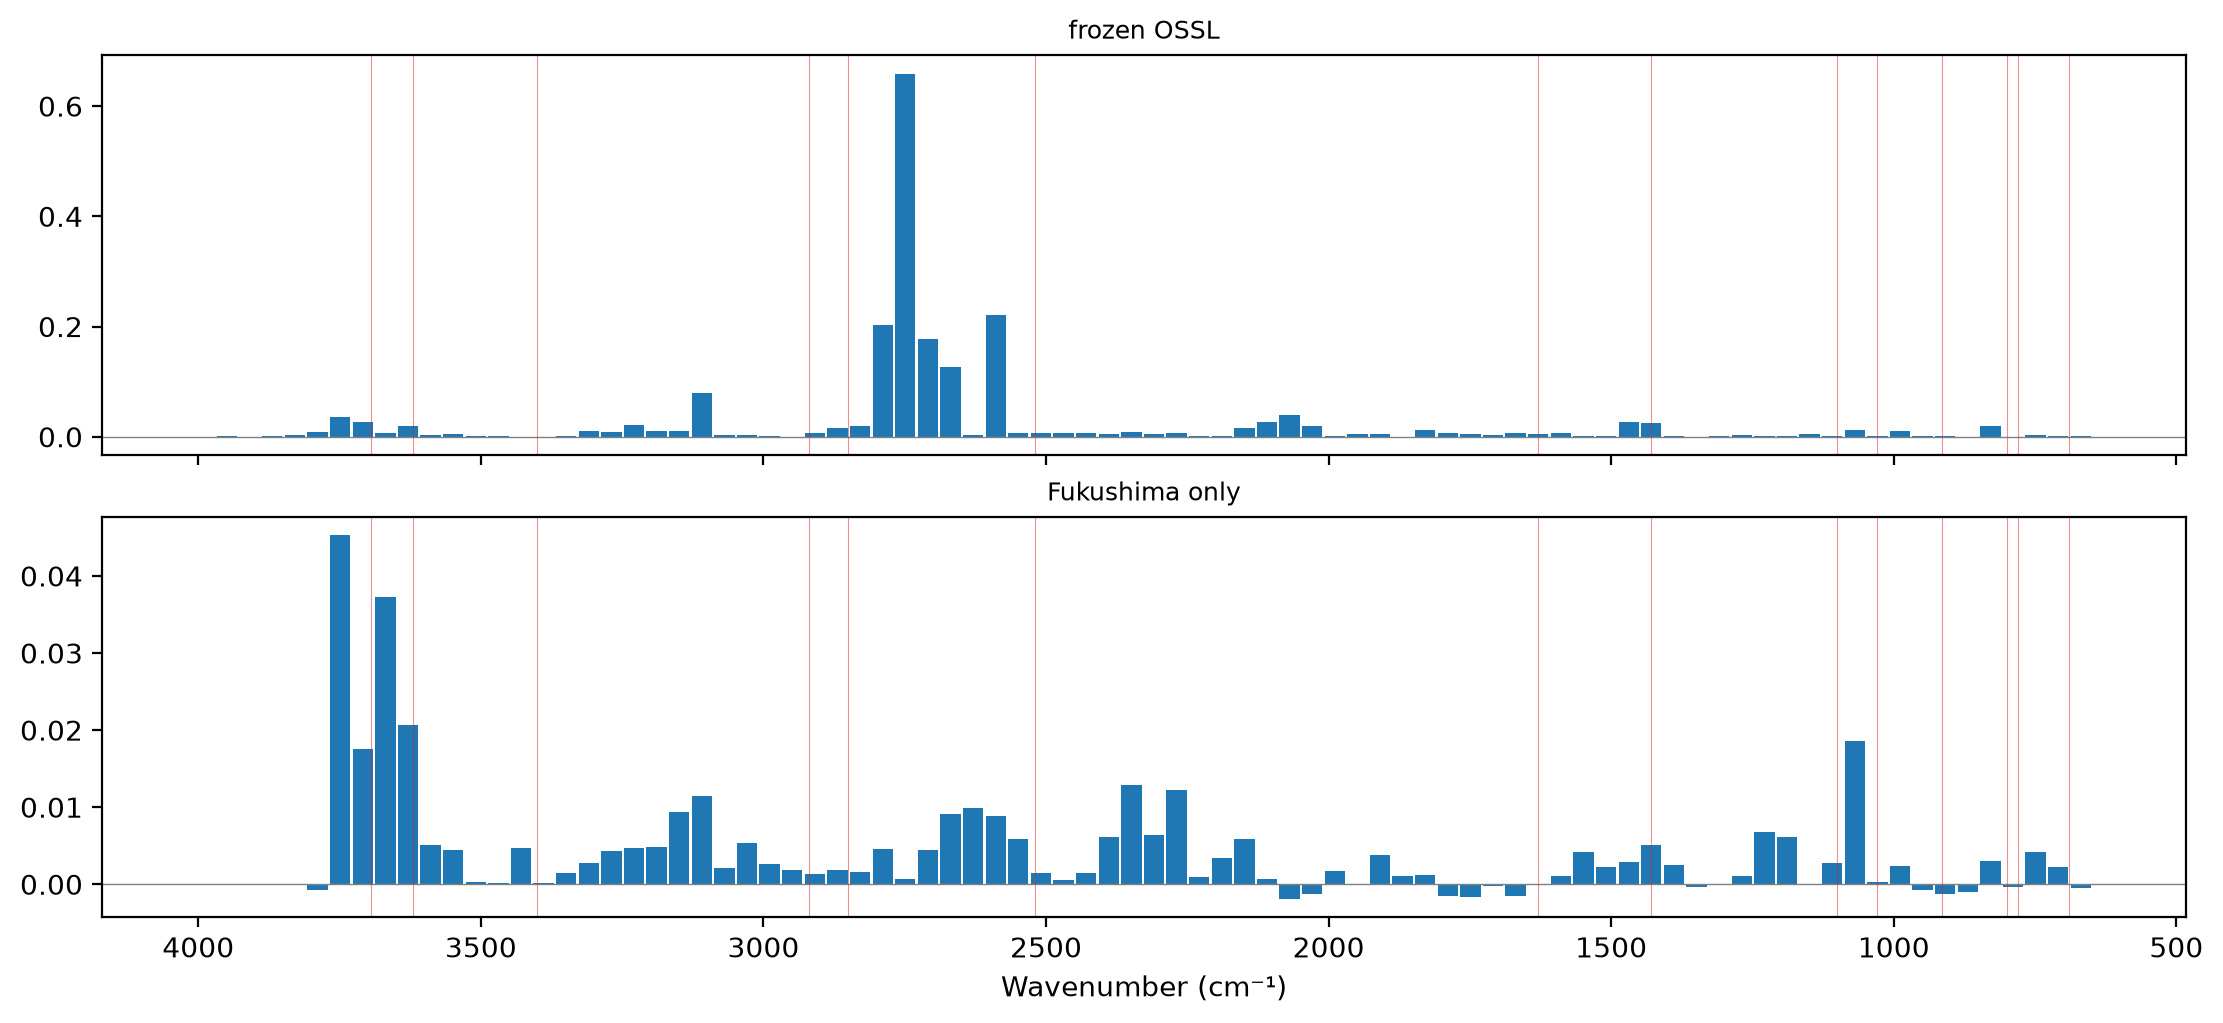

,frozen OSSL,Fukushima only
1,2749.0,3749.0
2,2589.0,3669.0
3,2789.0,3629.0
4,2709.0,1069.0
5,2669.0,3709.0


In [ ]:
#| fukudata
occ = {m: occlusion(model, Xf_d[is_test], yf[is_test]) for m, model in models.items()}
fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout='constrained')
for ax, (m, d) in zip(axs, occ.items()):
    ax.bar(d.wavenumber, d['rise in MSE'], width=36); ax.axhline(0, lw=0.5, c='grey'); ax.set_title(m, fontsize=9)
    for w in bands: ax.axvline(w, lw=0.4, c='tab:red', alpha=0.5)
axs[-1].invert_xaxis(); axs[-1].set_xlabel('Wavenumber (cm⁻¹)')
pd.DataFrame({m: d.nlargest(5, 'rise in MSE').wavenumber.round(0).to_numpy() for m, d in occ.items()}, index=range(1, 6))

## Clay-mineral bands and the ratio

The second-derivative depths of `18_aloh` on the SNV spectra, and their Spearman correlation with the Cs-137 ratio, overall and by soil type, with clay and Kex for context. Soil types with fewer than 30 samples are left out. Clay is missing for some samples, and each correlation uses the samples that have both values:

In [ ]:
#| fukudata
S = SNV().fit_transform(Xf)
depth = {b: band_depth(S, shared_wns, c) for b, (c, *_) in sharp_bands.items()}
pp = fuku_shared_props(idf)
cols = {'Cs ratio': yf, 'clay': pp['clay'].to_numpy(dtype=float), 'Kex': pp['K'].to_numpy(dtype=float)}
def rho(x, y, msk):
    ok = msk & np.isfinite(x) & np.isfinite(y)
    return spearmanr(x[ok], y[ok])[0] if ok.sum() >= 30 else np.nan
soil = pp['soil'].to_numpy()
groups = {'all': np.ones(len(yf), bool), **{s: soil == s for s in pd.Series(soil).dropna().value_counts().index}}
rows = {}
for g, msk in groups.items():
    r = {'n': int(msk.sum())}
    for b in sharp_bands:
        for k, y in cols.items(): r[f'{b} vs {k}'] = rho(depth[b], y, msk)
    r['Cs ratio vs clay'] = rho(yf, cols['clay'], msk)
    r['Cs ratio vs Kex'] = rho(yf, cols['Kex'], msk)
    rows[g] = r
pd.DataFrame(rows).T.round(3)

,n,Al–OH 3620 vs Cs ratio,Al–OH 3620 vs clay,Al–OH 3620 vs Kex,kaolinite 3695 vs Cs ratio,kaolinite 3695 vs clay,kaolinite 3695 vs Kex,Cs ratio vs clay,Cs ratio vs Kex
all,1389.0,-0.202,-0.186,-0.086,-0.205,-0.240,-0.033,0.038,-0.070
Lowland soil,907.0,-0.202,-0.307,-0.122,-0.187,-0.354,-0.064,0.116,-0.004
Andosols,213.0,-0.267,0.137,0.095,-0.260,0.054,0.139,-0.051,0.039
Forest soil,138.0,-0.038,-0.100,-0.156,-0.135,-0.185,-0.127,-0.082,-0.215
Peat soil,66.0,0.118,-0.111,-0.268,0.093,-0.199,-0.213,0.049,-0.492
Red yellow soil,46.0,-0.223,0.321,-0.091,-0.074,-0.059,-0.055,-0.214,-0.422
Glay soil,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Findings

The Fukushima-only CNN relies on the clay-mineral O–H region for the Cs-137 ratio. By integrated gradients, 11% of its importance lies in 3600–3700 cm⁻¹, more per cm⁻¹ than any other region. In the occlusion test, its most important window is centred at 3749 cm⁻¹, just above the clay-mineral O–H bands. The next are at 3669, 3629 and 3709 cm⁻¹, within them, and the fifth at 1069 cm⁻¹, in the Si–O region. Its test R² is 0.57 (r 0.76), with the Kex schedule, which was not tuned for the ratio.

The frozen-OSSL model relies on other regions. It draws 32% of its importance from 2000–2800 cm⁻¹ and 20% from 2800–3200 cm⁻¹, and only 3.6% from 3600–3700 cm⁻¹. Its five most important occlusion windows all lie between 2589 and 2789 cm⁻¹. The two models' profiles correlate at 0.36. Its ridge head reads standardised block-4 features, which gives large weights to features with little variance. Weak, quiet regions such as 2000–2800 cm⁻¹ may get their importance this way. Its test R² is 0.64 (r 0.81), the same as in `10_cs137`.

The clay-mineral bands relate to the Cs-137 ratio as fixation on clay minerals predicts. Deeper bands go with a smaller exchangeable fraction: Spearman −0.20 for the Al–OH band and −0.21 for the kaolinite band, over all 1,389 samples. The relation holds in the Lowland soils (−0.20 and −0.19, 907 samples) and in the Andosols (−0.27 and −0.26, 213 samples).

So the Cs-137 ratio does not show the reversal that clay shows. In the Lowland soils, the band depths correlate negatively with clay (−0.31 and −0.35), but negatively with the Cs-137 ratio too, as expected. The ratio itself correlates with clay at 0.12 in the Lowland soils and 0.04 overall, where fixation would predict a negative relation. The bands track the Cs-137 ratio as expected, and clay doesn't. The odd one out in the Lowland soils is more likely the clay values, or clay amount as a measure of the fixing minerals, than the bands. That is an interpretation of these correlations, not a test.

Kex correlates with the Cs-137 ratio at −0.49 in the 66 Peat soils, −0.42 in the 46 Red yellow soils and −0.22 in the 138 Forest soils, and near 0 in the Lowland soils and Andosols.